Метод              | x*        | f(x*)     | Длина интервала  | Итераций  | Вычислений f
-------------------------------------------------------------------------------------
Дихотомия          | 2.50008   | 1.00000   | 1.62588e-04      | 15        | 31
Золотое сечение    | 2.50004   | 1.00000   | 1.26253e-04      | 22        | 25
Фибоначчи          | 2.50000   | 1.00000   | 4.11898e-05      | 23        | 26


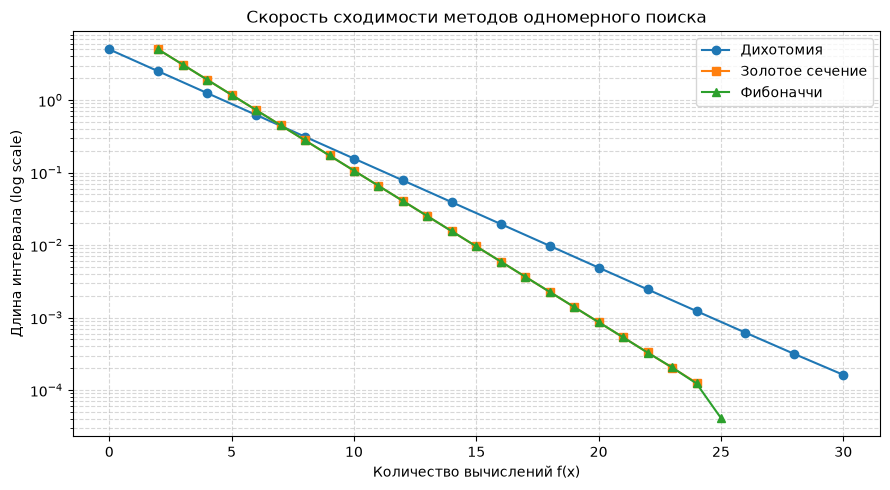

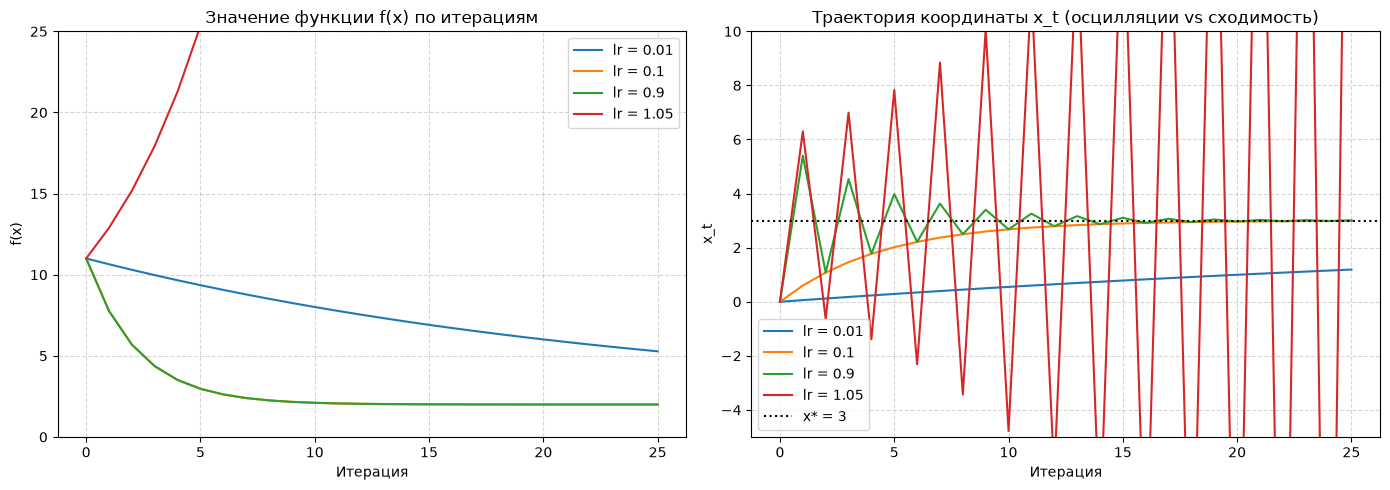

Итоговые веса линейной регрессии: w = 2.0175 (истина: 2.0), b = 1.0516 (истина: 1.0)
Финальный MSE: 1.0550


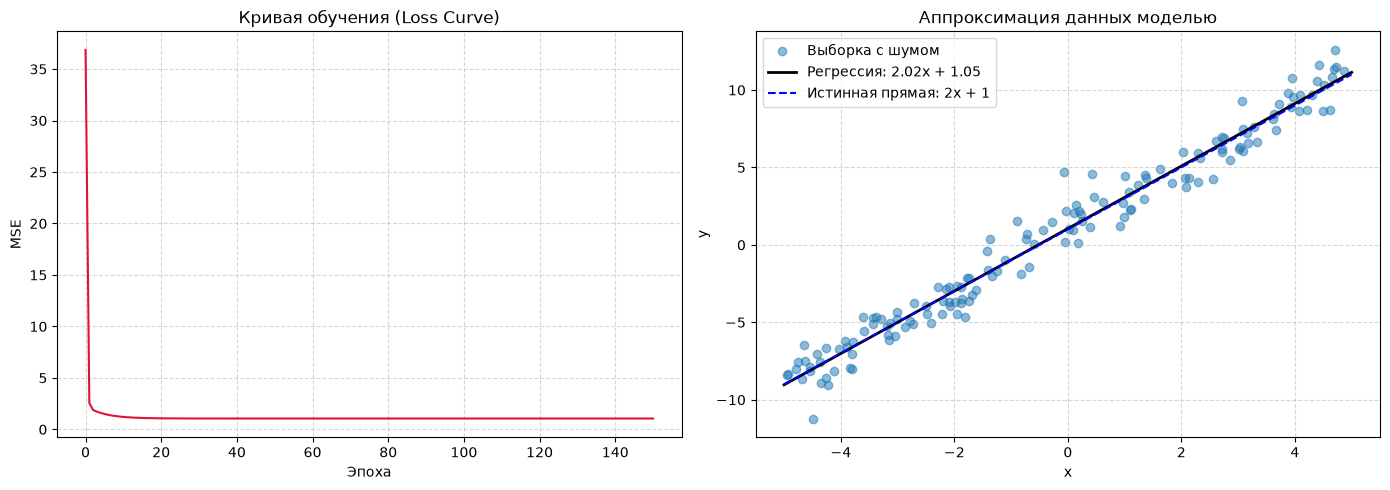

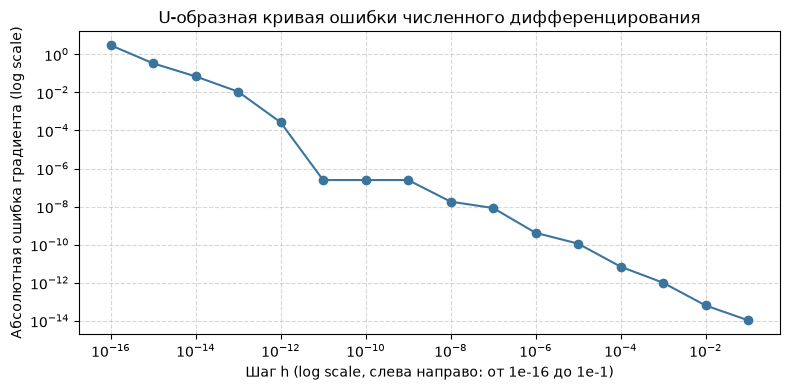

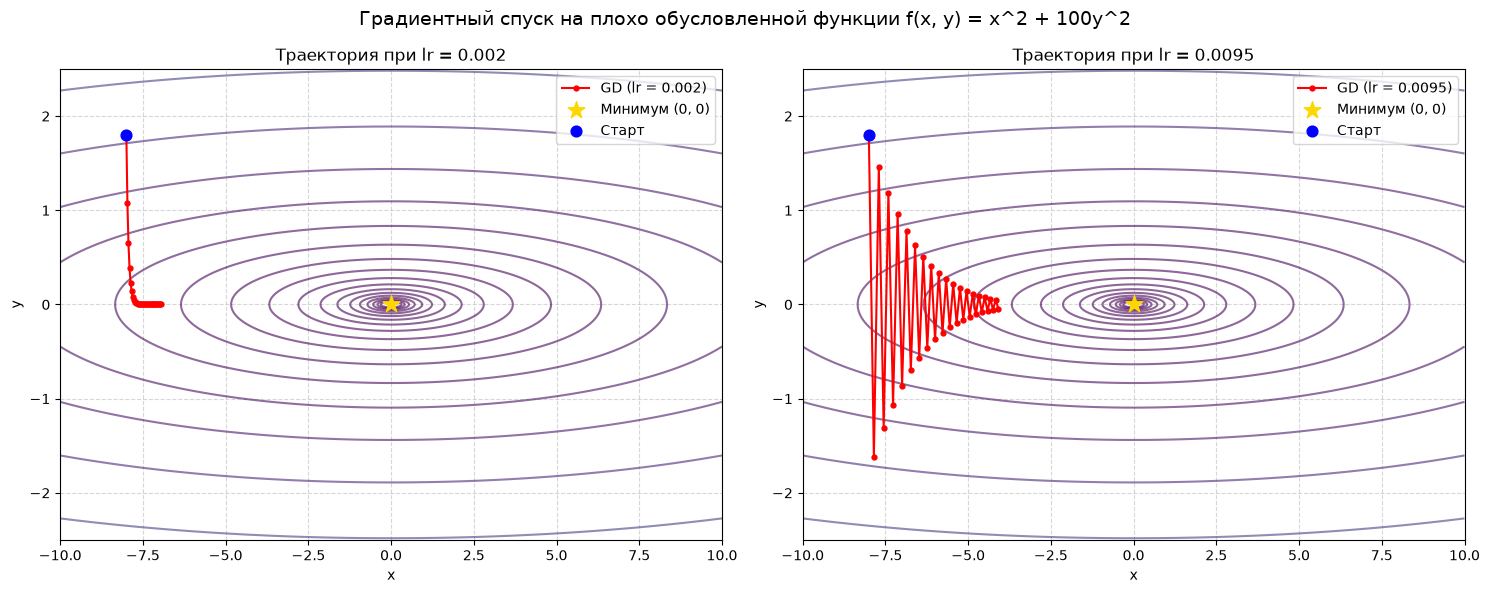

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# ЧАСТЬ A: ОДНОМЕРНЫЙ ПОИСК
# ==========================================

def target_f_opt(x):
    """Целевая унимодальная функция для Части A."""
    return (x - 2.5)**2 + 1.0

def dichotomy_search(f, a, b, delta, eps):
    assert eps < 2 * delta, "Параметр eps должен быть строго меньше 2 * delta"
    history_intervals = [b - a]
    history_evals = [0]
    feval_count = 0
    iteration = 0
    
    while (b - a) > 2 * delta:
        iteration += 1
        x1 = (a + b - eps) / 2.0
        x2 = (a + b + eps) / 2.0
        
        f1, f2 = f(x1), f(x2)
        feval_count += 2
        
        if f1 < f2:
            b = x2
        else:
            a = x1
            
        history_intervals.append(b - a)
        history_evals.append(feval_count)
        
    x_opt = (a + b) / 2.0
    return {
        "name": "Дихотомия",
        "x_opt": x_opt,
        "f_opt": f(x_opt),
        "final_interval_len": b - a,
        "iterations": iteration,
        "fevals": feval_count + 1,
        "history_intervals": history_intervals,
        "history_evals": history_evals
    }

def golden_section_search(f, a, b, delta):
    tau = (np.sqrt(5) - 1.0) / 2.0  # ~0.6180339887
    x1 = b - tau * (b - a)
    x2 = a + tau * (b - a)
    f1, f2 = f(x1), f(x2)
    feval_count = 2
    iteration = 0
    
    history_intervals = [b - a]
    history_evals = [feval_count]
    
    while (b - a) > 2 * delta:
        iteration += 1
        if f1 < f2:
            b = x2
            x2 = x1
            f2 = f1
            x1 = b - tau * (b - a)
            f1 = f(x1)
        else:
            a = x1
            x1 = x2
            f1 = f2
            x2 = a + tau * (b - a)
            f2 = f(x2)
            
        feval_count += 1
        history_intervals.append(b - a)
        history_evals.append(feval_count)
        
    x_opt = (a + b) / 2.0
    return {
        "name": "Золотое сечение",
        "x_opt": x_opt,
        "f_opt": f(x_opt),
        "final_interval_len": b - a,
        "iterations": iteration,
        "fevals": feval_count + 1,
        "history_intervals": history_intervals,
        "history_evals": history_evals
    }

def fibonacci_search(f, a, b, target_fevals):
    n = target_fevals
    fib = [0, 1]
    for i in range(2, n + 3):
        fib.append(fib[-1] + fib[-2])
        
    x1 = a + (fib[n - 1] / fib[n + 1]) * (b - a)
    x2 = a + (fib[n] / fib[n + 1]) * (b - a)
    f1, f2 = f(x1), f(x2)
    feval_count = 2
    iteration = 0
    
    history_intervals = [b - a]
    history_evals = [feval_count]
    
    for k in range(1, n - 1):
        iteration += 1
        if f1 < f2:
            b = x2
            x2 = x1
            f2 = f1
            x1 = a + (fib[n - k] / fib[n - k + 2]) * (b - a)
            f1 = f(x1)
        else:
            a = x1
            x1 = x2
            f1 = f2
            x2 = a + (fib[n - k + 1] / fib[n - k + 2]) * (b - a)
            f2 = f(x2)
            
        feval_count += 1
        history_intervals.append(b - a)
        history_evals.append(feval_count)
        
    eps = 1e-5 * (b - a)
    x2 = x1 + eps
    f2 = f(x2)
    feval_count += 1
    
    if f1 < f2:
        b = x2
    else:
        a = x1
        
    history_intervals.append(b - a)
    history_evals.append(feval_count)
    
    x_opt = (a + b) / 2.0
    return {
        "name": "Фибоначчи",
        "x_opt": x_opt,
        "f_opt": f(x_opt),
        "final_interval_len": b - a,
        "iterations": iteration + 1,
        "fevals": feval_count + 1,
        "history_intervals": history_intervals,
        "history_evals": history_evals
    }

# Запуск и построение Части A
a_bound, b_bound = 0.0, 5.0
delta_val = 1e-4
eps_val = 1e-5

res_dich = dichotomy_search(target_f_opt, a_bound, b_bound, delta_val, eps_val)
res_gold = golden_section_search(target_f_opt, a_bound, b_bound, delta_val)
res_fib = fibonacci_search(target_f_opt, a_bound, b_bound, res_gold["fevals"] - 1)

print("=" * 85)
print(f"{'Метод':<18} | {'x*':<9} | {'f(x*)':<9} | {'Длина интервала':<16} | {'Итераций':<9} | {'Вычислений f'}")
print("-" * 85)
for r in [res_dich, res_gold, res_fib]:
    print(f"{r['name']:<18} | {r['x_opt']:<9.5f} | {r['f_opt']:<9.5f} | {r['final_interval_len']:<16.5e} | {r['iterations']:<9} | {r['fevals']}")
print("=" * 85)

plt.figure(figsize=(9, 5))
plt.plot(res_dich["history_evals"], res_dich["history_intervals"], marker='o', label="Дихотомия")
plt.plot(res_gold["history_evals"], res_gold["history_intervals"], marker='s', label="Золотое сечение")
plt.plot(res_fib["history_evals"], res_fib["history_intervals"], marker='^', label="Фибоначчи")
plt.yscale('log')
plt.xlabel("Количество вычислений f(x)")
plt.ylabel("Длина интервала (log scale)")
plt.title("Скорость сходимости методов одномерного поиска")
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()

# ==========================================
# ЧАСТЬ B: ГРАДИЕНТНЫЙ СПУСК
# ==========================================

def target_f_b(x):
    return (x - 3.0)**2 + 2.0

def target_df_b(x):
    return 2.0 * (x - 3.0)

def gradient_descent(x_init, lr, iterations, f, df):
    x = x_init
    hist_x = [x]
    hist_f = [f(x)]
    for _ in range(iterations):
        x = x - lr * df(x)
        hist_x.append(x)
        hist_f.append(f(x))
    return np.array(hist_x), np.array(hist_f)

lrs = [0.01, 0.1, 0.9, 1.05]
x_start = 0.0
n_iter = 25

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for lr in lrs:
    h_x, h_f = gradient_descent(x_start, lr, n_iter, target_f_b, target_df_b)
    axes[0].plot(range(n_iter + 1), h_f, label=f"lr = {lr}")
    axes[1].plot(range(n_iter + 1), h_x, label=f"lr = {lr}")

axes[0].set_ylim(0, 25)
axes[0].set_xlabel("Итерация")
axes[0].set_ylabel("f(x)")
axes[0].set_title("Значение функции f(x) по итерациям")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].set_ylim(-5, 10)
axes[1].axhline(3.0, color='black', linestyle=':', label="x* = 3")
axes[1].set_xlabel("Итерация")
axes[1].set_ylabel("x_t")
axes[1].set_title("Траектория координаты x_t (осцилляции vs сходимость)")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# ==========================================
# ЧАСТЬ C: ЛИНЕЙНАЯ РЕГРЕССИЯ
# ==========================================

np.random.seed(42)
n_samples = 150
x_data = np.random.uniform(-5, 5, size=n_samples)
noise = np.random.normal(0, 1.0, size=n_samples)
y_data = 2.0 * x_data + 1.0 + noise

def compute_mse(w, b, x, y):
    return np.mean((w * x + b - y)**2)

def compute_gradients(w, b, x, y):
    error = (w * x + b) - y
    dw = (2.0 / len(x)) * np.sum(error * x)
    db = (2.0 / len(x)) * np.sum(error)
    return dw, db

w_cur, b_cur = 0.0, 0.0
lr_reg = 0.05
epochs = 150
loss_hist = [compute_mse(w_cur, b_cur, x_data, y_data)]

for _ in range(epochs):
    dw, db = compute_gradients(w_cur, b_cur, x_data, y_data)
    w_cur -= lr_reg * dw
    b_cur -= lr_reg * db
    loss_hist.append(compute_mse(w_cur, b_cur, x_data, y_data))

print(f"Итоговые веса линейной регрессии: w = {w_cur:.4f} (истина: 2.0), b = {b_cur:.4f} (истина: 1.0)")
print(f"Финальный MSE: {loss_hist[-1]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(loss_hist, color='crimson')
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("MSE")
axes[0].set_title("Кривая обучения (Loss Curve)")
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].scatter(x_data, y_data, alpha=0.5, label="Выборка с шумом")
x_line = np.linspace(-5, 5, 100)
axes[1].plot(x_line, w_cur * x_line + b_cur, color='black', lw=2, label=f"Регрессия: {w_cur:.2f}x + {b_cur:.2f}")
axes[1].plot(x_line, 2.0 * x_line + 1.0, '--', color='blue', label="Истинная прямая: 2x + 1")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].set_title("Аппроксимация данных моделью")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# ==========================================
# БОНУС 1: ЧИСЛЕННЫЙ VS АНАЛИТИЧЕСКИЙ ГРАДИЕНТ
# ==========================================

x_eval = 4.5
analytical_grad = target_df_b(x_eval)
h_powers = np.arange(1, 17)
h_values = 10.0**(-h_powers)
errors = []

for h in h_values:
    num_grad = (target_f_b(x_eval + h) - target_f_b(x_eval - h)) / (2.0 * h)
    errors.append(abs(num_grad - analytical_grad))

plt.figure(figsize=(8, 4))
plt.loglog(h_values, errors, marker='o', color='#3b759e')
plt.xlabel("Шаг h (log scale, слева направо: от 1e-16 до 1e-1)")
plt.ylabel("Абсолютная ошибка градиента (log scale)")
plt.title("U-образная кривая ошибки численного дифференцирования")
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.tight_layout()
plt.show()

# ==========================================
# БОНУС 2: ОВРАЖНАЯ ФУНКЦИЯ f(x, y) = x^2 + 100*y^2
# ==========================================

def ravine_f(x, y):
    return x**2 + 100.0 * y**2

def ravine_grad(x, y):
    return np.array([2.0 * x, 200.0 * y])

def gd_2d(start_point, lr, n_steps=40):
    point = np.array(start_point, dtype=float)
    trajectory = [point.copy()]
    for _ in range(n_steps):
        point -= lr * ravine_grad(point[0], point[1])
        trajectory.append(point.copy())
        if np.linalg.norm(point) > 1e4:
            break
    return np.array(trajectory)

start = [-8.0, 1.8]
lrs_to_test = [0.002, 0.0095]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
x_grid = np.linspace(-10, 10, 400)
y_grid = np.linspace(-2.5, 2.5, 400)
X, Y = np.meshgrid(x_grid, y_grid)
Z = ravine_f(X, Y)
levels = np.logspace(-1, 3.5, 20)

for ax, lr in zip(axes, lrs_to_test):
    traj = gd_2d(start, lr=lr, n_steps=35)
    ax.contour(X, Y, Z, levels=levels, cmap='viridis', alpha=0.6)
    ax.plot(traj[:, 0], traj[:, 1], 'r.-', linewidth=1.5, markersize=7, label=f"GD (lr = {lr})")
    ax.scatter([0], [0], color='gold', marker='*', s=160, zorder=5, label="Минимум (0, 0)")
    ax.scatter([start[0]], [start[1]], color='blue', s=60, zorder=5, label="Старт")
    ax.set_title(f"Траектория при lr = {lr}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.legend(loc="upper right")
    ax.grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Градиентный спуск на плохо обусловленной функции f(x, y) = x^2 + 100y^2", fontsize=14)
plt.tight_layout()
plt.show()